# Búsqueda de la señal de 794 nm (Rama B)

Montaje de la detección directa de la Rama B: el 822 nm (bombeo, 46 mW) y la semilla de 852 nm (500 µW) atraviesan copropagantes la celda de Cs a 60 °C. El láser de 794 nm está apagado, así que toda luz de 794 nm hacia adelante tendría que venir del medio. El 822 está fijo en el máximo de dos fotones (desintonía nominal 0 MHz) y se barre $\lambda_{852}$ a través de la D2 con una onda triangular de 40 mHz. La exposición del QuTau es de 100 ms.

* **Canal A** (PMT lateral): fluorescencia azul de la cascada $8S\to 7P\to 6S$. Con el 822 fijo muestra los valles sub-Doppler F′=3, 4 y 5 de la clase $v_z\approx 0$ (ver `Rama_B/Fluorescencia/`; a 60 °C y 500 µW también aparece el de F′=5), es decir, marca dónde el 852 es resonante con los átomos que excita el 822.
* **Canal B** (filtros ND → fibra → monocromador → SPCM): la luz que sale de la celda hacia adelante.

**Qué se espera.** La señal paramétrica $\propto|\chi^{(3)}_B|^2$ es resonante en $\delta_2 = \Delta_2 - \Delta_3 = 0$. Con el 822 en $\Delta_2 = 0$, eso ocurre cuando el 852 es resonante con 6S F=4 → 6P3/2 F′ para la misma clase de velocidad, o sea en las frecuencias de los valles del canal A. Una señal de FWM se vería en el canal B como **picos** en esas frecuencias, y solo con el monocromador cerca de la línea 8S F=4 → 6P3/2 (794.606 nm).

**Series** (todas a 60 °C):

| Serie | Monocromador | ND |
|---|---|---|
| 822 barrido solo (46 mW) | 794 nm | 10 |
| 852 barrido solo (500 µW) | 794 nm | 2, 4, 8, 10 |
| 852 barrido con el 822 fijo | 794 nm | 2, 4, 8, 10 |
| 852 barrido con el 822 fijo | 793.0 a 795.0 nm en pasos de 0.2 nm | 2 |

**Columnas:** col 0 no se usa, col 1 λ del láser barrido (nm), col 2 Singles A (cuentas/s), col 3 Singles B (cuentas/s), col 4 ν del láser barrido (THz).
**Nombre:** `<láser barrido>-[<desintonía del fijo>]-<P barrido>-[<P fijo>]-<λ monocromador>-<T>-<ND>.txt`, con los campos entre corchetes opcionales.

In [1]:
import sys
sys.path.append('../..')  # carpeta raíz del repositorio, donde está constants.py
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.ndimage import uniform_filter1d

from constants import c, kB, cte

C_LIGHT = c*1e-3  # nm*THz
BASE = '.'
T_EXP = 0.1  # tiempo de exposición del QuTau [s]
F_BAR = 40   # frecuencia de la onda triangular del láser barrido [mHz]

# Estructura hiperfina (THz), la misma de Rama_B/Fluorescencia. 6S y 6P3/2: Steck; 8S1/2: A = 219.125 MHz (Fendel et al. 2007)
HF_6S_F4 = 4.021776399375e-3
HF_6P = {5: 263.81e-6, 4: 12.815e-6, 3: -188.4885e-6}
HF_8S_F4 = 7/4 * 219.125e-6

NU_852 = cte['nu_ba[Hz]']*1e-12 - HF_6S_F4 + HF_6P[5]          # 6S F=4 -> 6P3/2 F'=5
NU_822 = (cte['nu_ca[Hz]']*1e-12 - HF_6S_F4 + HF_8S_F4) / 2    # mitad de 6S F=4 -> 8S F=4
NU_794 = {F: (cte['nu_ca[Hz]'] - cte['nu_ba[Hz]'])*1e-12 + HF_8S_F4 - HF_6P[F] for F in (5, 4, 3)}  # 8S F=4 -> 6P3/2 F'
DET_FP = {F: (HF_6P[F] - HF_6P[5])*1e6 for F in (5, 4, 3)}      # F' respecto a F'=5 (MHz)
LAM_794 = C_LIGHT/NU_794[4]

def doppler_fwhm(nu, T_C):
    # FWHM Doppler (MHz) de un haz a frecuencia nu (THz), átomos a T_C (°C)
    return nu*1e6*np.sqrt(8*kB*(T_C + 273.15)*np.log(2) / (cte['m_Cs[kg]']*c**2))

print(f'ν(F=4→F′=5)   = {NU_852:.6f} THz  (λ = {C_LIGHT/NU_852:.6f} nm)')
print(f'ν_TP/2        = {NU_822:.6f} THz  (λ = {C_LIGHT/NU_822:.6f} nm)')
print('λ 8S F=4 → 6P3/2 F′ (nm):', {F: round(C_LIGHT/v, 5) for F, v in NU_794.items()})
print('F′ respecto a F′=5 (MHz):', {F: round(v, 1) for F, v in DET_FP.items()})

C1, C2, C3, INK, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#8a8984'
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

ν(F=4→F′=5)   = 351.721961 THz  (λ = 852.356383 nm)
ν_TP/2        = 364.503080 THz  (λ = 822.468929 nm)
λ 8S F=4 → 6P3/2 F′ (nm): {5: 794.60645, 4: 794.60592, 3: 794.60549}
F′ respecto a F′=5 (MHz): {5: 0.0, 4: -251.0, 3: -452.3}


## Lectura

Se descartan las filas sin lectura válida del láser barrido (λ a más de 1 nm del láser del nombre) y las que tienen 0 cuentas en algún canal (las primeras lecturas de cada archivo). Los campos del nombre se reconocen por su sufijo (`MHz`, `mW`/`muW`, `nm`, `C`, `ND`), así que el orden de λ monocromador, T y ND puede variar. El barrido triangular se corta en rampas en los extremos de λ suavizada, como en `Rama_B/Fluorescencia/`.

In [2]:
def parse_name(path):
    # <láser barrido>-[<desint. fijo>]-<P barrido>-[<P fijo>]-<λ monocromador>-<T>-<ND>.txt
    f = os.path.basename(path)[:-4].split('-')
    meta = dict(laser=int(f[0]), det_fijo=None, P_fijo=None)
    P = []
    for s in f[1:]:
        if s.endswith('MHz'):
            meta['det_fijo'] = float(s[:-3])
        elif s.endswith('muW'):
            P.append(float(s[:-3])*1e-3)
        elif s.endswith('mW'):
            P.append(float(s[:-2]))
        elif s.endswith('ND'):
            meta['ND'] = int(s[:-2])
        elif s.endswith('C'):
            meta['T'] = float(s[:-1])
        else:
            meta['lam_mono'] = float(s.removesuffix('nm'))  # con o sin sufijo 'nm'
    meta['P'] = P[0]
    if len(P) > 1:
        meta['P_fijo'] = P[1]
    return meta

def load(path):
    meta = parse_name(path)
    d = np.loadtxt(path)
    k = (np.abs(d[:, 1] - meta['laser']) < 1) & (d[:, 2] > 0) & (d[:, 3] > 0)
    ref = NU_822 if meta['laser'] == 822 else NU_852
    t = np.linspace(0, 1, len(d))[k]  # orden de adquisición, para la deriva lenta
    return meta, dict(lam=d[k, 1], det=(d[k, 4] - ref)*1e6, A=d[k, 2], B=d[k, 3], t=t, n_desc=int((~k).sum()))

def ramps(lam, w=9, dist=40):
    # Índices de cada rampa del barrido triangular, cortando en los extremos de lambda
    s = uniform_filter1d(lam, w)
    t = np.sort(np.r_[find_peaks(s, distance=dist)[0], find_peaks(-s, distance=dist)[0]])
    edges = np.r_[0, t, len(lam)]
    return [np.arange(a, b) for a, b in zip(edges[:-1], edges[1:]) if b - a > 5]

def binned(x, y, bin_w):
    # Media y desviación estándar de y en bins de ancho bin_w (MHz)
    xb = np.floor(x/bin_w)*bin_w + bin_w/2
    ux = np.unique(xb)
    return ux, np.array([y[xb == u].mean() for u in ux]), np.array([y[xb == u].std() for u in ux])

def mark_Fp(ax):
    # Líneas verticales en las transiciones F=4 → F'=3, 4, 5 (átomos con v_z = 0)
    for F, x0 in DET_FP.items():
        ax.axvline(x0, ls='--', lw=0.8, color=GRID)
        ax.annotate(f"F′={F}", (x0, 1), xycoords=('data', 'axes fraction'), xytext=(2, -10),
                    textcoords='offset points', fontsize=8, color=GRID)

files = sorted(f for f in glob.glob(os.path.join(BASE, 'data', '*.txt')) if 'readme' not in f.lower())
F822 = [f for f in files if parse_name(f)['laser'] == 822]
FSOLO = sorted([f for f in files if parse_name(f)['laser'] == 852 and parse_name(f)['P_fijo'] is None],
               key=lambda f: parse_name(f)['ND'])
FCOMB = [f for f in files if parse_name(f)['laser'] == 852 and parse_name(f)['P_fijo'] is not None]
FMONO = sorted([f for f in FCOMB if parse_name(f)['ND'] == 2], key=lambda f: parse_name(f)['lam_mono'])
FND = sorted([f for f in FCOMB if parse_name(f)['lam_mono'] == 794], key=lambda f: parse_name(f)['ND'])

print(f"{'archivo':46s} {'barre':>5s} {'fijo':>13s} {'mono':>6s} {'ND':>3s} {'filas':>6s} {'desc.':>5s} {'rampas':>6s} {'rango (MHz)':>15s}")
for f in F822 + FSOLO + FMONO + [f for f in FND if f not in FMONO]:
    meta, d = load(f)
    fijo = f"{meta['P_fijo']:g} mW, {meta['det_fijo']:g} MHz" if meta['P_fijo'] else '—'
    print(f"{os.path.basename(f):46s} {meta['laser']:5d} {fijo:>13s} {meta['lam_mono']:6.1f} {meta['ND']:3d} "
          f"{len(d['A']) + d['n_desc']:6d} {d['n_desc']:5d} {len(ramps(d['lam'])):6d} {d['det'].min():7.0f}…{d['det'].max():.0f}")

archivo                                        barre          fijo   mono  ND  filas desc. rampas     rango (MHz)
822-46mW-60C-10ND-794.txt                        822             —  794.0  10    696     3      9    -663…1340
852-500muW-794nm-60C-2ND.txt                     852             —  794.0   2    423     2      4   -1228…389
852-500muW-794nm-60C-4ND.txt                     852             —  794.0   4    804     1      7   -1228…407
852-500muW-794nm-60C-8ND.txt                     852             —  794.0   8    551     3      5   -1183…431
852-500muW-794nm-60C-10ND.txt                    852             —  794.0  10   1710     4     15   -1104…511
852-0MHz-500muW-46mW-793nm-60C-2ND.txt           852  46 mW, 0 MHz  793.0   2    810     2      7   -1256…368
852-0MHz-500muW-46mW-793.2nm-60C-2ND.txt         852  46 mW, 0 MHz  793.2   2    569     1      6   -1267…366
852-0MHz-500muW-46mW-793.4nm-60C-2ND.txt         852  46 mW, 0 MHz  793.4   2    556     2      5   -1252…373
852-0

## 1. Barrido del 822 solo

Sirve de referencia para el canal A: da la altura máxima de la fluorescencia de dos fotones, con la que se compara la línea base de las tomas con el 822 fijo para saber si estaba en el máximo. El ajuste es una gaussiana más línea base sobre el promedio de todas las rampas (bins de 10 MHz). Las rampas de subida y de bajada se ajustan por separado para medir el corrimiento que produce la exposición de 100 ms.

Esta toma tiene ND 10, así que el canal B solo ve el piso del detector.

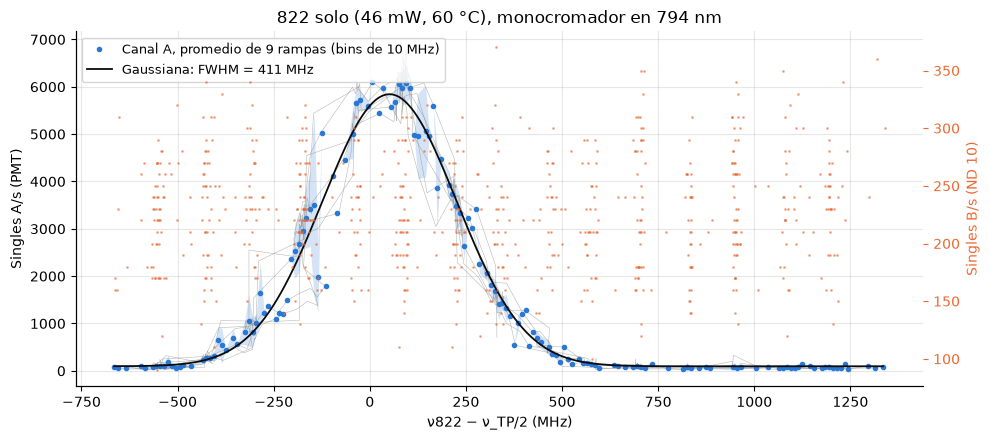

Centro: 51.3 ± 2.8 MHz  (λ0 = 822.468813 nm)
FWHM:   411.2 ± 7.8 MHz   (Doppler a 60 °C: 413.3 MHz)
Máximo: 5842 cuentas/s (línea base 96)
Centro con ν subiendo: 60 MHz, bajando: 29 MHz → diferencia 31 MHz
Canal B: 226 ± 49 cuentas/s (Poisson: ±48)


In [3]:
def gauss(x, c0, x0, s, a):
    return c0 + a*np.exp(-(x - x0)**2 / (2*s**2))

def fit_gauss(x, y):
    k = np.argmax(uniform_filter1d(y, 5))
    popt, pcov = curve_fit(gauss, x, y, p0=[np.percentile(y, 5), x[k], 150, y[k]], maxfev=20000)
    return popt, np.sqrt(np.diag(pcov))

meta822, d = load(F822[0])
segs = ramps(d['lam'])
x, m, s = binned(d['det'], d['A'], 10.0)
popt, perr = fit_gauss(x, m)
A_MAX_822 = popt[0] + popt[3]
fwhm_D = doppler_fwhm(NU_822, meta822['T'])

fig, ax = plt.subplots(figsize=(10, 4.5))
for sg in segs:
    ax.plot(d['det'][sg], d['A'][sg], '-', lw=0.4, color=GRID, alpha=0.6)
ax.fill_between(x, m - s, m + s, color=C1, alpha=0.2, lw=0)
ax.plot(x, m, 'o', ms=3, color=C1, label=f'Canal A, promedio de {len(segs)} rampas (bins de 10 MHz)')
xx = np.linspace(x.min(), x.max(), 2000)
ax.plot(xx, gauss(xx, *popt), '-', color=INK, lw=1.3, label=f'Gaussiana: FWHM = {2.3548*abs(popt[2]):.0f} MHz')
ax.set_xlabel('ν822 − ν_TP/2 (MHz)')
ax.set_ylabel('Singles A/s (PMT)')
ax.legend(loc='upper left', fontsize=9)
axb = ax.twinx()
axb.plot(d['det'], d['B'], '.', ms=2, color=C2, alpha=0.5)
axb.set_ylabel(f"Singles B/s (ND {meta822['ND']})", color=C2)
axb.tick_params(axis='y', colors=C2)
axb.grid(False)
ax.set_title(f"822 solo ({meta822['P']:g} mW, {meta822['T']:g} °C), monocromador en {meta822['lam_mono']:g} nm")
fig.tight_layout()
plt.show()

print(f'Centro: {popt[1]:.1f} ± {perr[1]:.1f} MHz  (λ0 = {C_LIGHT/(NU_822 + popt[1]*1e-6):.6f} nm)')
print(f'FWHM:   {2.3548*abs(popt[2]):.1f} ± {2.3548*perr[2]:.1f} MHz   (Doppler a {meta822["T"]:g} °C: {fwhm_D:.1f} MHz)')
print(f'Máximo: {A_MAX_822:.0f} cuentas/s (línea base {popt[0]:.0f})')

x0s = {+1: [], -1: []}
for sg in segs:
    if len(sg) < 60:  # rampas incompletas
        continue
    p, _ = fit_gauss(d['det'][sg], d['A'][sg])
    x0s[int(np.sign(d['det'][sg][-1] - d['det'][sg][0]))].append(p[1])
up, dn = np.mean(x0s[+1]), np.mean(x0s[-1])
print(f'Centro con ν subiendo: {up:.0f} MHz, bajando: {dn:.0f} MHz → diferencia {up - dn:.0f} MHz')
print(f"Canal B: {d['B'].mean():.0f} ± {d['B'].std():.0f} cuentas/s (Poisson: ±{np.sqrt(d['B'].mean()/T_EXP):.0f})")

## 2. Canal A con el 852 barrido y el 822 fijo

Igual que en `Rama_B/Fluorescencia/fluorescencia_temperatura.ipynb`: línea base lineal menos tres lorentzianas (valles F′=3, 4 y 5 de la clase $v_z\approx 0$), sobre el promedio de las rampas en bins de 10 MHz. Las semillas de F′=4 y F′=5 se ponen a las separaciones tabuladas del valle más profundo. La línea base se compara con el máximo del 822 solo. Si el 822 está a $\delta_1$ del máximo de dos fotones, selecciona otra clase de velocidad y los valles se corren en $\delta_1\,\nu_{852}/\nu_{822}$.

Las posiciones y los anchos de estos valles definen, para cada barrido, dónde debería aparecer una señal de FWM en el canal B (sección 4).

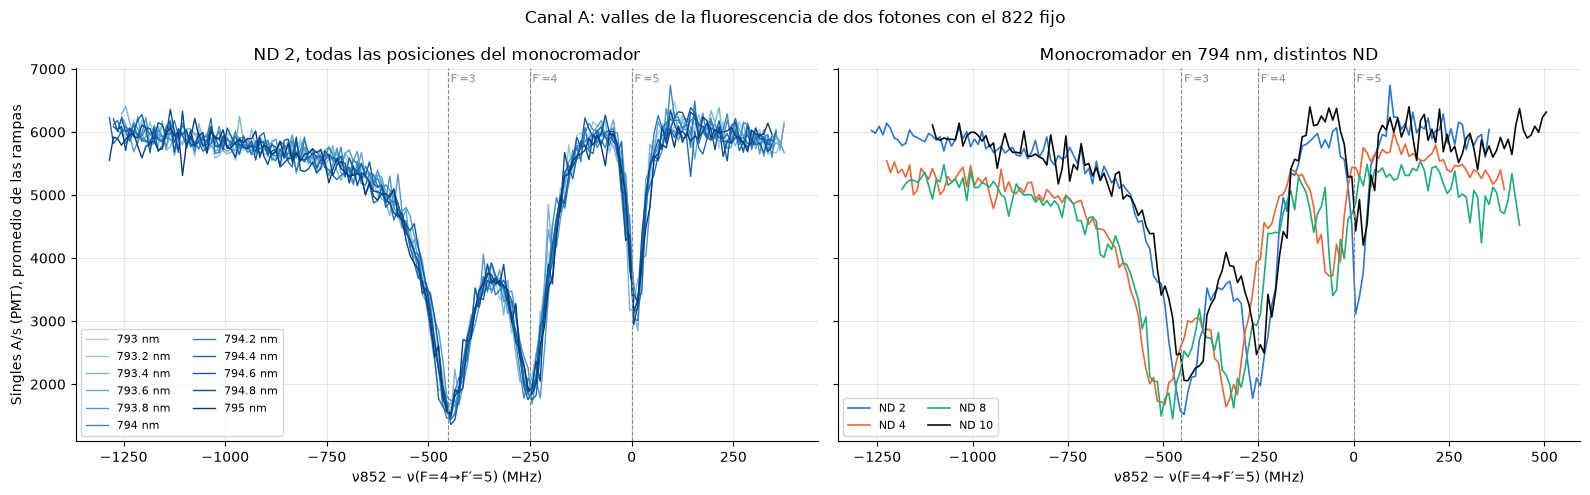

archivo                                         base b/máx | F′=3: x0 ± σ FWHM prof. | F′=4: x0 ± σ FWHM prof. | F′=5: x0 ± σ FWHM prof. | corr. δ1 impl.
852-0MHz-500muW-46mW-793nm-60C-2ND.txt          6127  1.05 |   -443 ± 2    163  4079 |   -252 ± 2     89  3661 |      9 ± 1     34  2661 |     6        6
852-0MHz-500muW-46mW-793.2nm-60C-2ND.txt        6110  1.05 |   -444 ± 2    161  4130 |   -253 ± 2     86  3698 |     12 ± 1     34  2837 |     6        6
852-0MHz-500muW-46mW-793.4nm-60C-2ND.txt        6129  1.05 |   -450 ± 2    168  4103 |   -258 ± 2     86  3677 |      9 ± 1     33  3346 |     1        1
852-0MHz-500muW-46mW-793.6nm-60C-2ND.txt        6089  1.04 |   -444 ± 2    161  4147 |   -255 ± 1     82  3661 |     11 ± 1     30  2865 |     5        5
852-0MHz-500muW-46mW-793.8nm-60C-2ND.txt        6135  1.05 |   -437 ± 2    158  4093 |   -242 ± 1     84  3879 |     16 ± 1     36  2807 |    13       14
852-0MHz-500muW-46mW-794nm-60C-2ND.txt          6158  1.05 |   -446 ± 2    1

In [4]:
def lorentz(x, x0, g, a):
    return a*(g/2)**2 / ((x - x0)**2 + (g/2)**2)

def dips(x, c0, c1, *p):
    return c0 + c1*x*1e-3 - sum(lorentz(x, *p[i:i + 3]) for i in range(0, len(p), 3))

def fit_dips(x, y):
    # Valle más profundo (F'=3) + F'=4 y F'=5 a las separaciones tabuladas. Devuelve {F: (x0, FWHM, prof.)} y errores
    c0 = np.percentile(y, 90)
    k = np.argmin(uniform_filter1d(y, 3))
    p0 = [c0, 0]
    for F, g0 in ((3, 150), (4, 90), (5, 40)):
        p0 += [x[k] + DET_FP[F] - DET_FP[3], g0, 0.8*(c0 - y[k])]
    popt, pcov = curve_fit(dips, x, y, p0=p0, maxfev=20000)
    perr = np.sqrt(np.diag(pcov))
    js = sorted(range(2, 11, 3), key=lambda j: popt[j])  # ordena por frecuencia: F'=3, 4, 5
    val = {F: (popt[j], abs(popt[j + 1]), popt[j + 2]) for F, j in zip((3, 4, 5), js)}
    err = {F: perr[j:j + 3] for F, j in zip((3, 4, 5), js)}
    return popt, val, err

resA = {}
for f in FCOMB:
    meta, d = load(f)
    x, m, s = binned(d['det'], d['A'], 10.0)
    popt, val, err = fit_dips(x, m)
    resA[f] = dict(meta, x=x, m=m, popt=popt, base=popt[0], val=val, err=err)

fig, axs = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
blues = plt.cm.Blues(np.linspace(0.35, 0.95, len(FMONO)))
for f, col in zip(FMONO, blues):
    R = resA[f]
    axs[0].plot(R['x'], R['m'], '-', lw=1, color=col, label=f"{R['lam_mono']:g} nm")
axs[0].set_title('ND 2, todas las posiciones del monocromador')
for f, col in zip(FND, [C1, C2, C3, INK]):
    R = resA[f]
    axs[1].plot(R['x'], R['m'], '-', lw=1.2, color=col, label=f"ND {R['ND']}")
axs[1].set_title('Monocromador en 794 nm, distintos ND')
for ax in axs:
    mark_Fp(ax)
    ax.set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
    ax.legend(fontsize=8, ncol=2, loc='lower left')
axs[0].set_ylabel('Singles A/s (PMT), promedio de las rampas')
fig.suptitle('Canal A: valles de la fluorescencia de dos fotones con el 822 fijo', fontsize=12)
fig.tight_layout()
plt.show()

print(f"{'archivo':46s} {'base':>5s} {'b/máx':>5s} |" + ''.join(f" {f'F′={F}: x0 ± σ':>12s} {'FWHM':>4s} {'prof.':>5s} |" for F in (3, 4, 5))
      + f" {'corr.':>5s} {'δ1 impl.':>8s}")
for f in FMONO + [f for f in FND if f not in FMONO]:
    R = resA[f]
    R['shift'] = np.mean([R['val'][F][0] - DET_FP[F] for F in (3, 4, 5)])
    cols = ''.join(f" {R['val'][F][0]:6.0f} ± {R['err'][F][0]:<3.0f} {R['val'][F][1]:4.0f} {R['val'][F][2]:5.0f} |" for F in (3, 4, 5))
    print(f"{os.path.basename(f):46s} {R['base']:5.0f} {R['base']/A_MAX_822:5.2f} |{cols} {R['shift']:5.0f} {R['shift']*NU_822/NU_852:8.0f}")
print(f"\nTabulado (MHz): F′=3 en {DET_FP[3]:.1f}, F′=4 en {DET_FP[4]:.1f}, F′=5 en 0. x0 y FWHM en MHz, profundidad en cuentas/s. "
      f"'corr.' = corrimiento medio de los valles respecto a lo tabulado; 'δ1 impl.' = desintonía del 822 que lo explicaría.")

## 3. ¿Qué ve el canal B?

Con ND 2 el canal B cambia mucho al barrer el 852: tiene un pozo ancho que llega casi al piso entre ≈ −250 y +150 MHz. Es la **semilla de 852 nm transmitida por la celda** que llega al SPCM a pesar del monocromador, con el perfil de absorción Doppler de la D2 en una celda ópticamente gruesa. El 852 solo muestra el mismo pozo.

Para comparar formas, cada promedio se normaliza a 1 lejos de resonancia ($\nu_{852} < -900$ MHz) y a 0 en el fondo del pozo ($|\nu_{852}| < 150$ MHz). Si todas las curvas coinciden, la forma de B la fija la transmisión del 852 y no depende del 822 ni del monocromador.

El piso del detector se toma de las tomas del 852 solo con ND 8 y 10, donde B no cambia con el barrido.

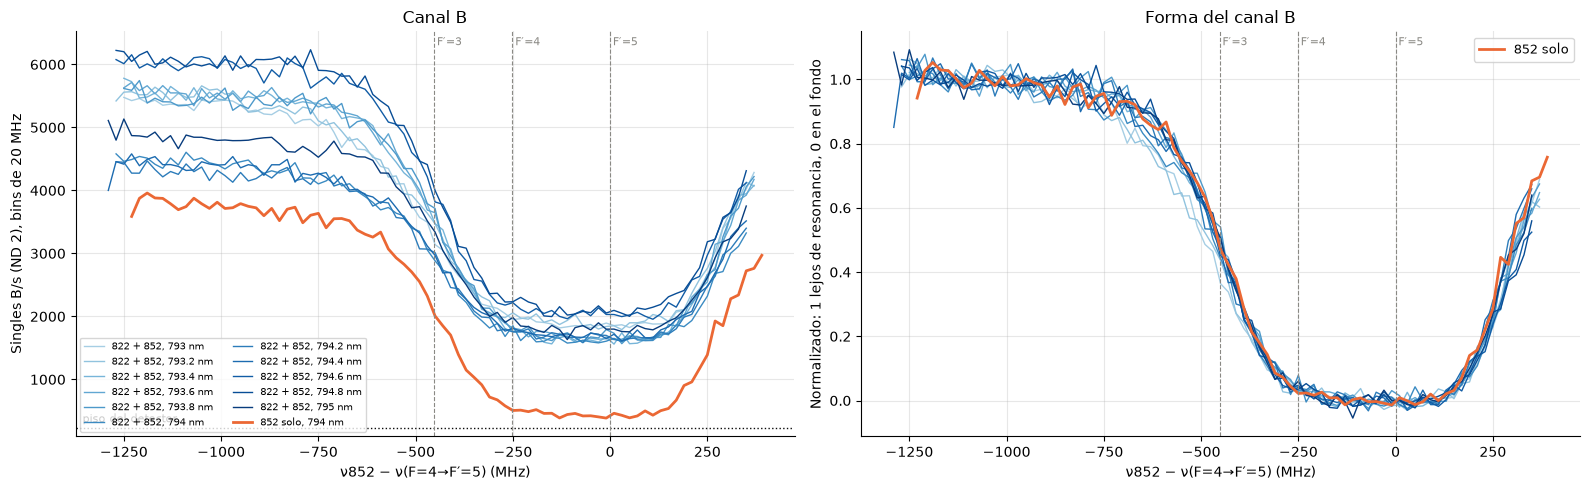

Piso del detector (852 solo, ND 8 y 10): 231 cuentas/s
Transmisión mínima del 852 en la plantilla: 0.058


In [5]:
FLOOR = np.mean([load(f)[1]['B'].mean() for f in FSOLO if parse_name(f)['ND'] >= 8])

def norm_profile(f, bin_w=20.0):
    meta, d = load(f)
    x, m, _ = binned(d['det'], d['B'], bin_w)
    off, bot = m[x < -900].mean(), m[np.abs(x) < 150].mean()
    return meta, x, m, (m - bot)/(off - bot)

# Plantilla de transmisión del 852, del 852 solo con ND 2: T = 1 lejos de resonancia y T = 0 en el piso del detector
meta_T, XT, mT, _ = norm_profile([f for f in FSOLO if parse_name(f)['ND'] == 2][0])
mT = uniform_filter1d(mT, 3)
TT = (mT - FLOOR)/(mT[XT < -900].mean() - FLOOR)

def T852(x):
    return np.interp(x, XT, TT)

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for f, col in zip(FMONO, blues):
    meta, x, m, n = norm_profile(f)
    axs[0].plot(x, m, '-', lw=1, color=col, label=f"822 + 852, {meta['lam_mono']:g} nm")
    axs[1].plot(x, n, '-', lw=1, color=col)
for f in FSOLO:
    if parse_name(f)['ND'] == 2:
        meta, x, m, n = norm_profile(f)
        axs[0].plot(x, m, '-', lw=2, color=C2, label='852 solo, 794 nm')
        axs[1].plot(x, n, '-', lw=2, color=C2, label='852 solo')
axs[0].axhline(FLOOR, ls=':', color=INK, lw=1)
axs[0].annotate('piso del detector', (axs[0].get_xlim()[0], FLOOR), xytext=(5, 4), textcoords='offset points', fontsize=8)
axs[0].set_ylabel('Singles B/s (ND 2), bins de 20 MHz')
axs[0].set_title('Canal B')
axs[1].set_ylabel('Normalizado: 1 lejos de resonancia, 0 en el fondo')
axs[1].set_title('Forma del canal B')
axs[1].legend(fontsize=9)
axs[0].legend(fontsize=7, ncol=2)
for ax in axs:
    mark_Fp(ax)
    ax.set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
fig.tight_layout()
plt.show()

print(f'Piso del detector (852 solo, ND 8 y 10): {FLOOR:.0f} cuentas/s')
print(f'Transmisión mínima del 852 en la plantilla: {TT[np.abs(XT) < 150].mean():.3f}')

## 4. Prueba: ¿hay en el canal B una componente ligada a los valles del canal A?

Con la forma de la transmisión tomada de la plantilla del 852 solo, se ajusta

$$B = b_0 + b_t\,(t - \tfrac12) + s\,T_{852}\!\left(x_c + \frac{x - x_c - \delta x}{w}\right) + \sum_{F'=3,4,5} b_{F'}\,L_{F'}(x),$$

donde $x = \nu_{852} - \nu(F{=}4\to F'{=}5)$ y:

* $b_0$ es lo que queda cuando el 852 está absorbido: el piso del detector más la luz que el 822 manda al SPCM.
* $s$ es la luz del 852 que llega al SPCM fuera de resonancia.
* $\delta x$ corre la plantilla (deriva del medidor de onda entre tomas) y $w$ la estira alrededor del centro del pozo, $x_c = -100$ MHz. El ancho del pozo de absorción cambia con la potencia del 852, que no es exactamente la misma en todas las tomas. Con ND ≥ 8 el 852 no se ve, y se fijan $\delta x = 0$ y $w = 1$.
* $b_t$ es una deriva lenta en el tiempo de adquisición.
* $L_{F'}(x)$ es una lorentziana de altura 1 con el centro y el ancho del valle F′ del canal A del mismo barrido (sección 2). Es la forma de la resonancia de la clase $v_z\approx 0$ en cada F′.

Una señal de FWM daría $b_{F'} > 0$: picos en B donde el 852 es resonante con la clase que excita el 822. Con $b_{F'} < 0$, B baja donde baja la población de 8S.

**Incertidumbre.** El residuo no es ruido blanco: con ND 2 su dispersión es mayor que la de Poisson, por fluctuaciones de la luz entre rampas. Por eso, además del error del ajuste, se ajusta cada rampa completa por separado (con $\delta x$ y $w$ fijos) y se toma el error de cada $b_{F'}$ como el mayor entre el del ajuste y la dispersión entre rampas dividida entre $\sqrt{n}$.

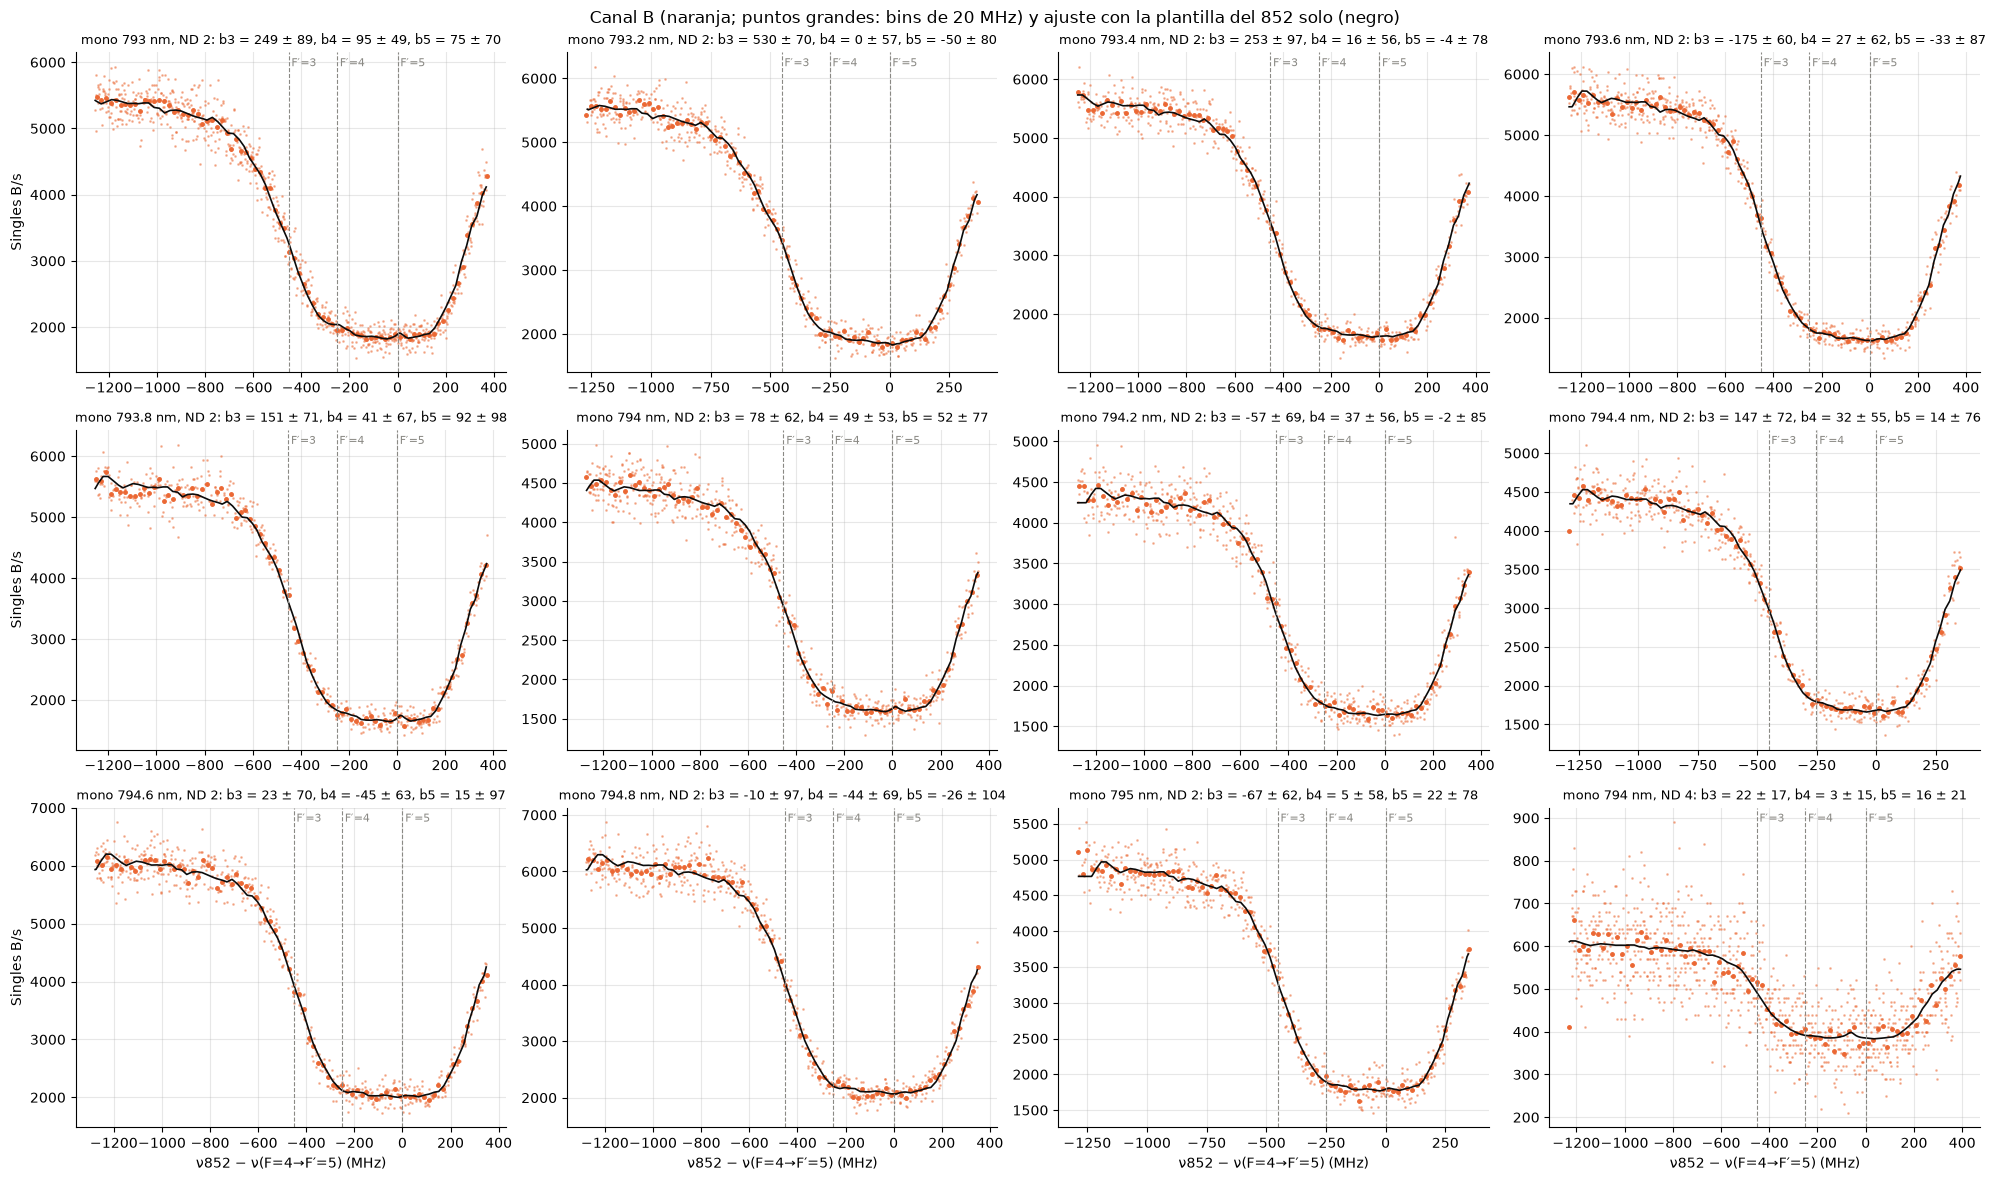

In [6]:
XC = -100.0  # centro del pozo de absorción del 852 (MHz)
FPS = (3, 4, 5)

def T852w(x, dx, w):
    return T852(XC + (x - XC - dx)/w)

def peaks(R, x):
    # Lorentzianas de altura 1 en los valles F'=3, 4, 5 del canal A del mismo barrido
    return np.array([lorentz(x, R['val'][F][0], R['val'][F][1], 1) for F in FPS])

def model_B(x, t, L, b0, bt, s, b3, b4, b5, dx=0.0, w=1.0):
    return b0 + bt*(t - 0.5) + s*T852w(x, dx, w) + b3*L[0] + b4*L[1] + b5*L[2]

def fit_B(f):
    meta, d = load(f)
    x, B, t = d['det'], d['B'], d['t']
    L = peaks(resA[f], x)
    free = meta['ND'] <= 4
    p0 = [B.min(), 0, B.max() - B.min(), 0, 0, 0] + ([0, 1] if free else [])
    popt, pcov = curve_fit(lambda X, *p: model_B(x, t, L, *p), x, B, p0=p0)
    perr = np.sqrt(np.diag(pcov))
    dx, w = (popt[6], popt[7]) if free else (0.0, 1.0)
    resid = B - model_B(x, t, L, *popt)

    # Rampa por rampa (con dx y w fijos): mínimos cuadrados lineales en b0, s, b3, b4, b5
    per = []
    for sg in ramps(d['lam']):
        if len(sg) < 100:
            continue
        M = np.c_[np.ones(len(sg)), T852w(x[sg], dx, w), L[:, sg].T]
        per.append(np.linalg.lstsq(M, B[sg], rcond=None)[0])
    per = np.array(per)
    e_r = per.std(axis=0, ddof=1)/np.sqrt(len(per))
    b = dict(zip(FPS, popt[3:6]))
    e = {F: max(perr[3 + i], e_r[2 + i]) for i, F in enumerate(FPS)}
    return dict(meta, name=os.path.basename(f), x=x, B=B, t=t, L=L, popt=popt, b0=popt[0], s=popt[2],
                b=b, e=e, z={F: b[F]/e[F] for F in FPS}, dx=dx, w=w,
                edx=perr[6] if free else np.nan, ew=perr[7] if free else np.nan, n_r=len(per),
                lim=max((max(b[F], 0) + 2*e[F]) for F in FPS)/popt[0],
                sB=resid.std(), sP=np.sqrt(np.mean(B)/T_EXP), resid=resid)

resB = {f: fit_B(f) for f in FCOMB}

FIT_PLOT = FMONO + [f for f in FND if parse_name(f)['ND'] == 4]
fig, axs = plt.subplots(3, 4, figsize=(20, 12))
for ax, f in zip(axs.flat, FIT_PLOT):
    R = resB[f]
    ax.plot(R['x'], R['B'], '.', ms=2, color=C2, alpha=0.4)
    xb, mb, sb = binned(R['x'], R['B'], 20.0)
    ax.plot(xb, mb, 'o', ms=2.5, color=C2)
    xs = np.linspace(R['x'].min(), R['x'].max(), 1500)
    ax.plot(xs, model_B(xs, 0.5, peaks(resA[f], xs), *R['popt']), '-', color=INK, lw=1.2)
    mark_Fp(ax)
    ax.set_title(f"mono {R['lam_mono']:g} nm, ND {R['ND']}: " + ', '.join(f"b{F} = {R['b'][F]:.0f} ± {R['e'][F]:.0f}" for F in FPS),
                 fontsize=9)
for ax in axs[:, 0]:
    ax.set_ylabel('Singles B/s')
for ax in axs[-1]:
    ax.set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
fig.suptitle('Canal B (naranja; puntos grandes: bins de 20 MHz) y ajuste con la plantilla del 852 solo (negro)', fontsize=12)
fig.tight_layout()
plt.show()

Residuos del ajuste **sin** los términos $b_{F'}L_{F'}$, promediados en bins de 20 MHz y desplazados verticalmente según la posición del monocromador. La curva azul es $200\sum_{F'} L_{F'}(x)$, la forma que tendría una señal de FWM de 200 cuentas/s en cada F′.

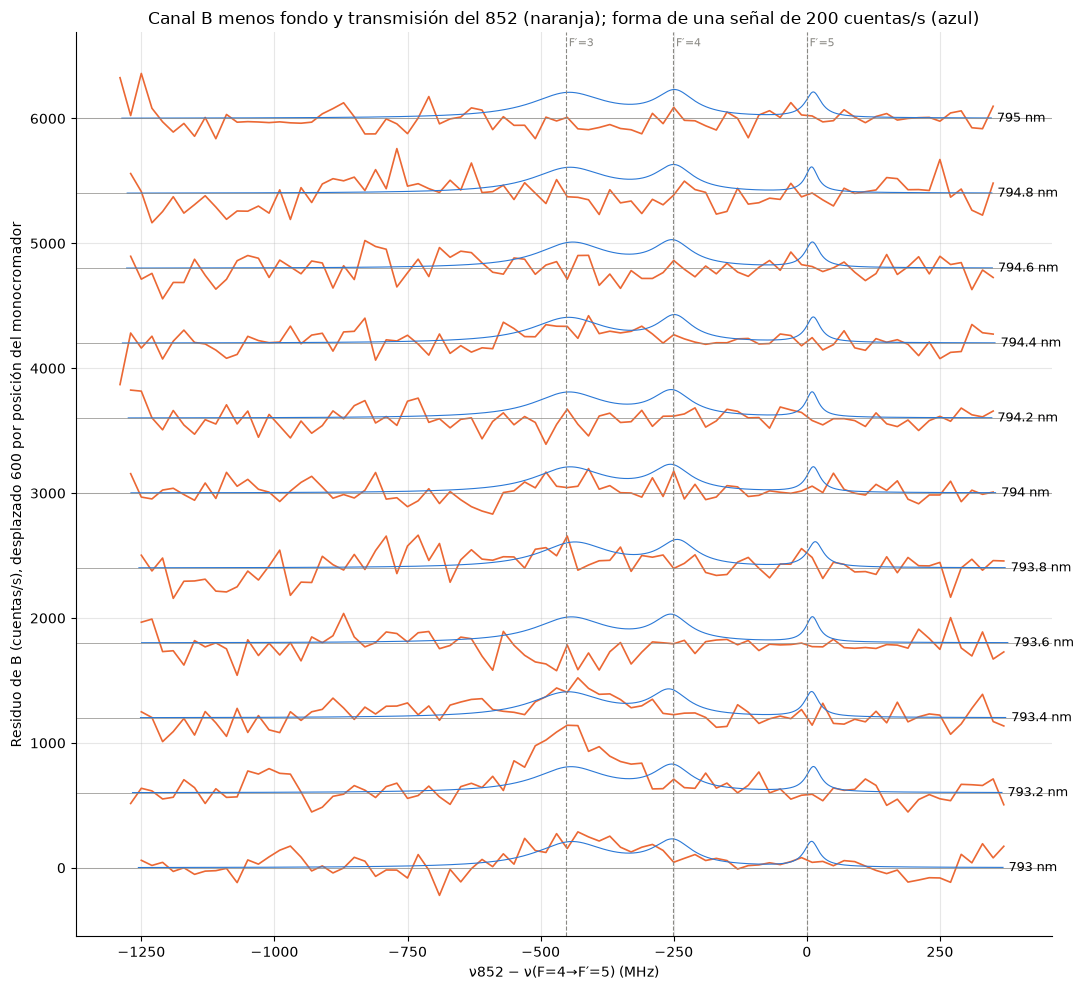

  mono  ND    b0     s       δx           w |      b3 ± σ    z |      b4 ± σ    z |      b5 ± σ    z | lím. 2σ  σ_B Pois. ramp.
 793.0   2  1615  3793 -21 ± 2  1.10 ± 0.01 |  249 ± 89    2.8 |   95 ± 49    1.9 |   75 ± 70    1.1 |   26.5%  211   192     6
 793.2   2  1647  3898 -28 ± 2  1.12 ± 0.01 |  530 ± 70    7.6 |    0 ± 57    0.0 |  -50 ± 80   -0.6 |   40.6%  198   197     4
 793.4   2  1392  4189  -3 ± 2  1.05 ± 0.01 |  253 ± 97    2.6 |   16 ± 56    0.3 |   -4 ± 78   -0.1 |   32.1%  195   195     4
 793.6   2  1440  4140  11 ± 2  1.02 ± 0.00 | -175 ± 60   -2.9 |   27 ± 62    0.4 |  -33 ± 87   -0.4 |   12.1%  213   199     4
 793.8   2  1422  4099   3 ± 2  1.03 ± 0.00 |  151 ± 71    2.1 |   41 ± 67    0.6 |   92 ± 98    0.9 |   20.6%  202   193     3
 794.0   2  1433  2998  -2 ± 3  1.04 ± 0.01 |   78 ± 62    1.3 |   49 ± 53    0.9 |   52 ± 77    0.7 |   14.4%  187   180     4
 794.2   2  1496  2827  -2 ± 3  1.01 ± 0.01 |  -57 ± 69   -0.8 |   37 ± 56    0.7 |   -2 ± 85   -0.0 |  

In [7]:
fig, ax = plt.subplots(figsize=(11, 10))
step = 600
for i, f in enumerate(FMONO):
    R = resB[f]
    r0 = R['resid'] + sum(R['b'][F]*R['L'][j] for j, F in enumerate(FPS))
    xb, mb, _ = binned(R['x'], r0, 20.0)
    ax.plot(xb, mb + i*step, '-', lw=1.2, color=C2)
    xs = np.linspace(R['x'].min(), R['x'].max(), 1500)
    ax.plot(xs, 200*peaks(resA[f], xs).sum(axis=0) + i*step, '-', lw=0.8, color=C1)
    ax.axhline(i*step, color=GRID, lw=0.5)
    ax.annotate(f"{R['lam_mono']:g} nm", (R['x'].max(), i*step), xytext=(4, 0), textcoords='offset points',
                fontsize=9, va='center')
mark_Fp(ax)
ax.set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
ax.set_ylabel(f'Residuo de B (cuentas/s), desplazado {step} por posición del monocromador')
ax.set_title('Canal B menos fondo y transmisión del 852 (naranja); forma de una señal de 200 cuentas/s (azul)')
fig.tight_layout()
plt.show()

print(f"{'mono':>6s} {'ND':>3s} {'b0':>5s} {'s':>5s} {'δx':>8s} {'w':>11s} |"
      + ''.join(f" {f'b{F} ± σ':>11s} {'z':>4s} |" for F in FPS) + f" {'lím. 2σ':>7s} {'σ_B':>4s} {'Pois.':>5s} {'ramp.':>5s}")
for f in FMONO + [f for f in FND if f not in FMONO]:
    R = resB[f]
    cols = ''.join(f" {R['b'][F]:4.0f} ± {R['e'][F]:<4.0f} {R['z'][F]:4.1f} |" for F in FPS)
    print(f"{R['lam_mono']:6.1f} {R['ND']:3d} {R['b0']:5.0f} {R['s']:5.0f} {R['dx']:3.0f} ± {R['edx']:<2.0f} "
          f"{R['w']:4.2f} ± {R['ew']:<4.2f} |{cols} {100*R['lim']:6.1f}% {R['sB']:4.0f} {R['sP']:5.0f} {R['n_r']:5d}")
print("\nb0, s, b_F′ y σ en cuentas/s; δx en MHz; lím. 2σ = max_F′(max(b_F′, 0) + 2σ)/b0; "
      "σ_B = dispersión de los residuos; Pois. = sqrt(<B>/T_exp).")

## 5. Dependencia con el monocromador y con el filtro ND

Una señal de 794 nm, sea de FWM o de fluorescencia de 8S → 6P3/2, solo pasa el monocromador cuando este está cerca de 794.606 nm. La luz de 822 y de 852 que se cuela no debería depender de la posición del monocromador en un intervalo de 2 nm. Se grafican frente a la posición del monocromador:

* la luz del 822, $b_0 - $ piso, y la del 852, $s$;
* su cociente, que cancela los cambios de acople a la fibra entre tomas;
* las amplitudes $b_{F'}$ ligadas a la resonancia de la clase $v_z\approx 0$.

Frente al filtro ND se usan niveles medidos directamente, sin modelo: B lejos de resonancia ($x < -900$ MHz) y en el fondo del pozo ($|x| < 150$ MHz), con y sin el 822.

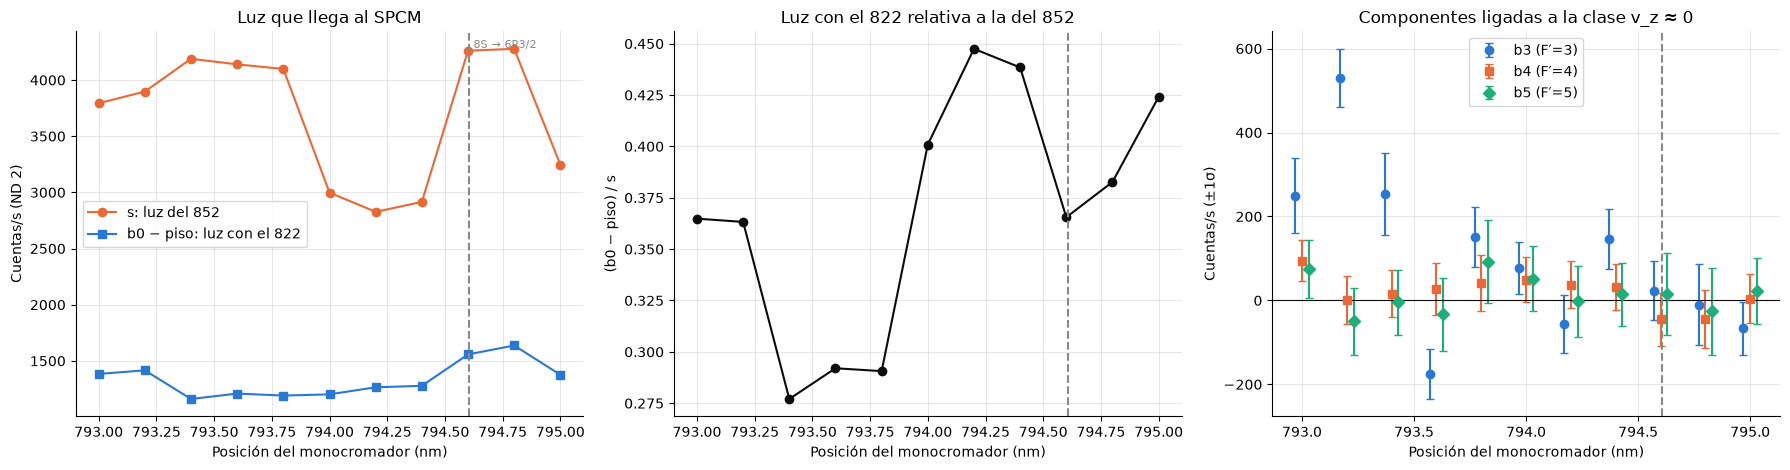

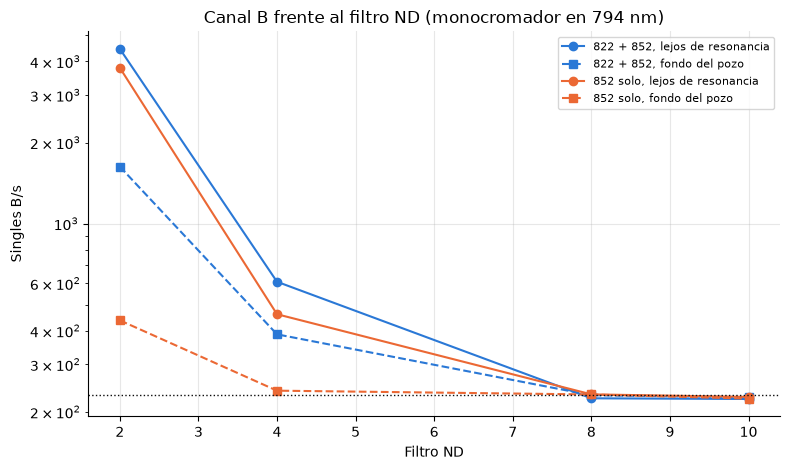

archivo                                          lejos   fondo
852-0MHz-500muW-46mW-794nm-60C-2ND.txt            4455    1627
852-0MHz-500muW-46mW-794nm-60C-4ND.txt             608     388
852-0MHz-500muW-46mW-794nm-60C-8ND.txt             224     230
852-0MHz-500muW-46mW-794nm-60C-10ND.txt            223     226
852-500muW-794nm-60C-2ND.txt                      3789     437
852-500muW-794nm-60C-4ND.txt                       461     240
852-500muW-794nm-60C-8ND.txt                       232     232
852-500muW-794nm-60C-10ND.txt                      227     224
Piso del detector: 231 cuentas/s


In [8]:
lm = np.array([resB[f]['lam_mono'] for f in FMONO])
L822 = np.array([resB[f]['b0'] - FLOOR for f in FMONO])
L852 = np.array([resB[f]['s'] for f in FMONO])

fig, axs = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axs[0]
ax.plot(lm, L852, 'o-', color=C2, label='s: luz del 852')
ax.plot(lm, L822, 's-', color=C1, label='b0 − piso: luz con el 822')
ax.set_ylabel('Cuentas/s (ND 2)')
ax.set_title('Luz que llega al SPCM')
ax.legend()
ax = axs[1]
ax.plot(lm, L822/L852, 'o-', color=INK)
ax.set_ylabel('(b0 − piso) / s')
ax.set_title('Luz con el 822 relativa a la del 852')
ax = axs[2]
for j, (F, col, mk) in enumerate(zip(FPS, (C1, C2, C3), 'osD')):
    ax.errorbar(lm + 0.03*(j - 1), [resB[f]['b'][F] for f in FMONO], yerr=[resB[f]['e'][F] for f in FMONO],
                fmt=mk, capsize=3, color=col, label=f'b{F} (F′={F})')
ax.axhline(0, color=INK, lw=0.8)
ax.set_ylabel('Cuentas/s (±1σ)')
ax.set_title('Componentes ligadas a la clase v_z ≈ 0')
ax.legend()
for ax in axs:
    ax.axvline(LAM_794, ls='--', color=GRID)
    ax.set_xlabel('Posición del monocromador (nm)')
axs[0].annotate('8S → 6P3/2', (LAM_794, 1), xycoords=('data', 'axes fraction'), xytext=(3, -12),
                textcoords='offset points', fontsize=8, color=GRID)
fig.tight_layout()
plt.show()

def levels(f):
    _, d = load(f)
    return d['B'][d['det'] < -900].mean(), d['B'][np.abs(d['det']) < 150].mean()

fig, ax = plt.subplots(figsize=(8, 4.8))
for F, col, lab in ((FND, C1, '822 + 852'), (FSOLO, C2, '852 solo')):
    nd = [parse_name(f)['ND'] for f in F]
    lv = np.array([levels(f) for f in F])
    ax.semilogy(nd, lv[:, 0], 'o-', color=col, label=f'{lab}, lejos de resonancia')
    ax.semilogy(nd, lv[:, 1], 's--', color=col, label=f'{lab}, fondo del pozo')
ax.axhline(FLOOR, ls=':', color=INK, lw=1)
ax.set_xlabel('Filtro ND')
ax.set_ylabel('Singles B/s')
ax.set_title('Canal B frente al filtro ND (monocromador en 794 nm)')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"{'archivo':46s} {'lejos':>7s} {'fondo':>7s}")
for f in FND + FSOLO:
    off, bot = levels(f)
    print(f"{os.path.basename(f):46s} {off:7.0f} {bot:7.0f}")
print(f'Piso del detector: {FLOOR:.0f} cuentas/s')

## Conclusiones

* **822 solo:** el pico de dos fotones tiene FWHM = 411 ± 8 MHz, frente a 413 MHz de Doppler a 60 °C, así que es enteramente Doppler. El centro queda a +51 MHz de $\nu_{TP}/2$ tabulado (+47 MHz en `Rama_B/Fluorescencia/` a 80 °C), que es el corrimiento absoluto del medidor de onda. Con 100 ms de exposición y 40 mHz de barrido, las rampas de subida y de bajada se separan 31 MHz.
* **Canal A con el 822 fijo:** aparecen los tres valles de la clase $v_z\approx 0$, en ≈ −445, −252 y +11 MHz (F′=3, 4 y 5), con FWHM ≈ 160, 86 y 33 MHz.
  * En la serie con ND 2 y en la de ND 10, la línea base es 1.04–1.05 veces el máximo del 822 solo, así que el 822 estaba en el máximo de dos fotones.
  * En las tomas con ND 4 y ND 8, los valles están corridos −63 y −49 MHz y la línea base baja a 0.96 y 0.89. Es compatible con que el 822 estuviera ≈ 50–65 MHz por debajo del máximo en esas dos tomas.
* **Origen del canal B:** con ND 2, B es casi todo **luz de la semilla de 852 nm que atraviesa la celda** y llega al SPCM pese al monocromador. Tiene el pozo de absorción Doppler de la D2 (transmisión mínima ≈ 6 %) con la misma forma con y sin el 822. A eso se suma un nivel constante de 1150–1650 cuentas/s que solo aparece con el 822 encendido: es luz del 822.
  * Ninguna de las dos depende de la posición del monocromador entre 793 y 795 nm. La luz del 852 varía entre 2800 y 4300 cuentas/s y la del 822 entre 1150 y 1650, y su cociente entre 0.28 y 0.45, sin máximo en 794.6 nm.
  * Con ND 8 y 10, B está en el piso del detector (231 cuentas/s).
  * Pasar de ND 2 a ND 4 atenúa ≈ 15 veces la luz del 852 y ≈ 9 veces la del 822.
* **Prueba de FWM:**
  * $b_4$ y $b_5$ son compatibles con cero en todas las tomas ($|z| \le 1.9$).
  * $b_3$ sale positivo con el monocromador en 793.0–793.4 nm (hasta 7.6σ en 793.2 nm). Pero en esas tomas la plantilla tuvo que deformarse más ($w$ = 1.05–1.12), y el exceso es más ancho que el valle F′=3, que cae en pleno flanco de absorción. Es un desajuste de la forma de la transmisión, no luz de 794 nm.
  * Con el monocromador en 794.6 y 794.8 nm, las tres amplitudes son compatibles con cero. Cualquier señal con la forma de los valles de A es menor que ≈ 210 cuentas/s con ND 2 (2σ), frente a ≈ 4300 cuentas/s de luz del 852 fuera de resonancia.

  **No se detecta señal de 794 nm.**
* **Ruido:** una vez ajustada la forma de la transmisión, la dispersión de B es 1.0–1.15 veces la de Poisson con $T_{exp}$ = 100 ms.

**Limitación principal:** en esta configuración el monocromador no separa el 794 de los haces de 822 y 852 nm. La sensibilidad la fija la luz del 852 que se cuela y no la estadística.

Siguientes pasos:
1. Calibrar el monocromador con el láser de 794 nm (el de la Rama A): transmisión frente a la posición y ancho de banda.
2. Medir B con el monocromador lejos de 794 nm (por ejemplo, 780 y 810 nm) para ver si la luz de 822 y 852 es luz difusa dentro del monocromador.
3. Poner un filtro interferencial de 794 nm antes de la fibra, para bloquear el 822 y el 852 y poder quitar los filtros ND.